In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost

In [2]:
print(xgboost.__version__)

1.7.4


In [4]:
names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks', 
                               'class_information']
len(names)

28

In [5]:
features = ["MDVP:Fo(Hz)","MDVP:Fhi(Hz)","MDVP:Flo(Hz)","MDVP:Jitter(%)","MDVP:Jitter(Abs)","MDVP:RAP","MDVP:PPQ","Jitter:DDP","MDVP:Shimmer","MDVP:Shimmer(dB)","Shimmer:APQ3","Shimmer:APQ5","MDVP:APQ","Shimmer:DDA","NHR","HNR","RPDE","DFA","spread1","spread2","D2","PPE","status"]


In [6]:
len(features)

23

In [7]:
pd.set_option('display.max_columns', None)
pd.set_option('max_colwidth', None)

In [22]:
dataset = pd.read_csv ('data.csv', names=features) 

dataset.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE,status
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,0.02182,0.03130,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654,1
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,0.03134,0.04518,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674,1
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,0.02757,0.03858,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634,1
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,0.02924,0.04005,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975,1
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,0.03490,0.04825,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335,1


In [23]:
dataset.drop(['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 
              'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:Shimmer(dB)', 
              'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:DDA', 'NHR', 'HNR',
              'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE'], 
             axis=1, inplace=True)

dataset.head()

,MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:APQ,status
0,0.00370,0.00554,0.01109,0.04374,0.02971,1
1,0.00465,0.00696,0.01394,0.06134,0.04368,1
2,0.00544,0.00781,0.01633,0.05233,0.03590,1
3,0.00502,0.00698,0.01505,0.05492,0.03772,1
4,0.00655,0.00908,0.01966,0.06425,0.04465,1


In [25]:
df_test = pd.read_csv ('youtube_data.txt', delimiter=",", header=0, index_col = [0], 
                        names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks', 
                               'class_information']) 
df_test.tail()

,Jitter_local,Jitter_local_absolute,Jitter_rap,Jitter_ppq5,Jitter_ddp,Shimmer_local,Shimmer_local_dB,Shimmer_apq3,Shimmer_apq5,Shimmer_apq11,Shimmer_dda,AC,NTH,HTN,Median_pitch,Mean_pitch,Standard_deviation,Minimum_pitch,Maximum_pitch,Number_of_pulses,Number_of_periods,Mean_period,Standard_deviation_of_period,Fraction_of_locally_unvoiced_frames,Number_of_voice_breaks,Degree_of_voice_breaks,class_information
id,,,,,,,,,,,,,,,,,,,,,,,,,,,
30,0.538,0.000033,0.315,0.302,0.945,5.812,0.589,2.880,3.474,4.835,8.641,0.969972,0.033313,16.858,168.292,165.331,10.242,142.897,180.228,162.0,161.0,0.006054,0.000389,0.000,0.0,0.000,1
30,0.569,0.000033,0.286,0.282,0.859,5.347,0.607,2.459,3.098,4.943,7.378,0.958033,0.056643,19.555,178.424,174.325,16.922,81.122,189.771,167.0,165.0,0.005787,0.000938,2.062,1.0,2.971,1
30,0.680,0.000036,0.368,0.305,1.103,2.968,0.326,1.369,1.707,2.438,4.108,0.979590,0.030422,22.116,188.775,186.116,7.420,155.230,192.402,182.0,181.0,0.005363,0.000201,0.000,0.0,0.000,1
30,0.353,0.000019,0.158,0.129,0.474,3.101,0.317,1.554,1.911,2.691,4.662,0.987098,0.014819,22.981,188.711,186.255,6.774,151.195,192.318,182.0,181.0,0.005365,0.000196,0.000,0.0,0.000,1
30,1.172,0.000064,0.604,0.701,1.813,3.354,0.429,1.662,1.900,2.494,4.987,0.957209,0.058446,21.232,187.763,184.279,7.470,158.926,191.998,181.0,180.0,0.005432,0.000270,0.000,0.0,0.000,1


In [26]:
df_test.drop(['Jitter_local','Jitter_local_absolute',
              'Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5',   
              'Shimmer_dda', 'AC','NTH','HTN','Median_pitch','Mean_pitch',
              'Standard_deviation','Minimum_pitch','Maximum_pitch',
              'Number_of_pulses','Number_of_periods','Mean_period',
              'Standard_deviation_of_period','Fraction_of_locally_unvoiced_frames',
              'Number_of_voice_breaks','Degree_of_voice_breaks'], 
             axis=1, inplace=True)

df_test.head()

,Jitter_rap,Jitter_ppq5,Jitter_ddp,Shimmer_local,Shimmer_apq11,class_information
id,,,,,,
1,0.073,0.081,0.219,1.236,0.894,1
1,0.087,0.089,0.260,1.338,1.017,1
1,0.075,0.089,0.224,1.086,0.823,1
1,0.080,0.097,0.240,1.049,0.777,1
1,0.077,0.095,0.230,1.241,1.568,1


In [27]:
df_test.rename(columns = {'Jitter_rap': 'MDVP:RAP',
                          'Jitter_ppq5': 'MDVP:PPQ',
                          'Jitter_ddp': 'Jitter:DDP',
                          'Shimmer_local': 'MDVP:Shimmer',
                          'Shimmer_apq11': 'MDVP:APQ',
                          'class_information': 'status'}, inplace=True)

In [28]:
df_test.head()

,MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:APQ,status
id,,,,,,
1,0.073,0.081,0.219,1.236,0.894,1
1,0.087,0.089,0.260,1.338,1.017,1
1,0.075,0.089,0.224,1.086,0.823,1
1,0.080,0.097,0.240,1.049,0.777,1
1,0.077,0.095,0.230,1.241,1.568,1


In [16]:
len(dataset)

195

In [9]:
len(features)

23

In [10]:
names=['id',
                                'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks',
                               'UPDRS', 
                               'class_information']

In [11]:
len(names)

29

In [19]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MDVP:RAP      195 non-null    float64
 1   MDVP:PPQ      195 non-null    float64
 2   Jitter:DDP    195 non-null    float64
 3   MDVP:Shimmer  195 non-null    float64
 4   MDVP:APQ      195 non-null    float64
dtypes: float64(5)
memory usage: 7.7 KB


### Boxplot of training data (dataset)

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'MDVP:RAP'),
  Text(1, 0, 'MDVP:PPQ'),
  Text(2, 0, 'Jitter:DDP'),
  Text(3, 0, 'MDVP:Shimmer'),
  Text(4, 0, 'MDVP:APQ')])

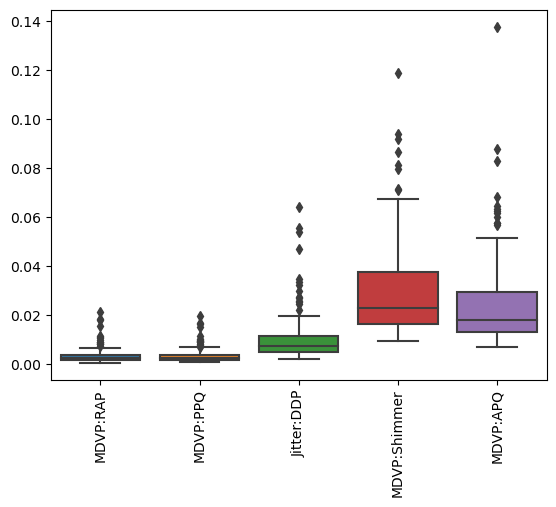

In [20]:
sns.boxplot(data=dataset)
plt.xticks(rotation=90)

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'MDVP:RAP'),
  Text(1, 0, 'MDVP:PPQ'),
  Text(2, 0, 'Jitter:DDP'),
  Text(3, 0, 'MDVP:Shimmer'),
  Text(4, 0, 'MDVP:APQ')])

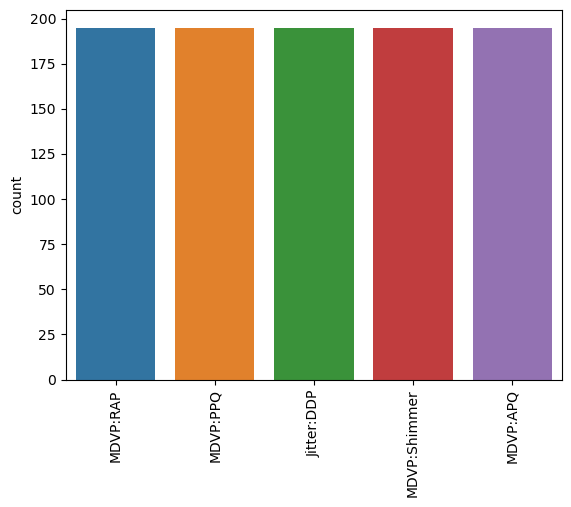

In [21]:
sns.countplot(data=dataset)
plt.xticks(rotation=90)

In [29]:
# store the dataset as an array for easier processing
array = dataset.values
# X stores feature values
X = array[:,0:5]
# Y stores "status"
Y = array[:,5]

In [30]:
from sklearn import model_selection
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X, Y, test_size = 0.4, random_state = 7)


In [31]:
# 10-fold cross validation to estimate accuracy (split data into 10 parts; use 9 parts to train and 1 for test)
num_folds = 10
num_instances = len(X_train)
seed = 7
# use the 'accuracy' metric to evaluate models (correct / total)
scoring = 'accuracy'

In [32]:
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [33]:
# algorithms / models
models = []
models.append(('LR', LogisticRegression()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('DT', DecisionTreeClassifier()))
models.append(('GB', GradientBoostingClassifier(n_estimators=10000)))

Scores for each algorithm:
LR 78.2051282051282
0.0
[[ 0 17]
 [ 0 61]]
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00        17
         1.0       0.78      1.00      0.88        61

    accuracy                           0.78        78
   macro avg       0.39      0.50      0.44        78
weighted avg       0.61      0.78      0.69        78



/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


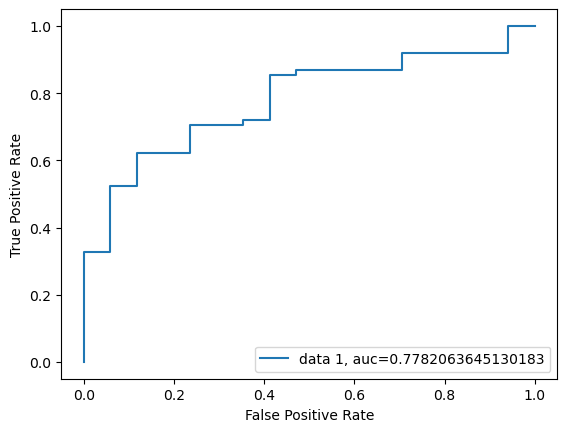


KNN 74.35897435897436
0.3096582404335979
[[ 9  8]
 [12 49]]
              precision    recall  f1-score   support

         0.0       0.43      0.53      0.47        17
         1.0       0.86      0.80      0.83        61

    accuracy                           0.74        78
   macro avg       0.64      0.67      0.65        78
weighted avg       0.77      0.74      0.75        78



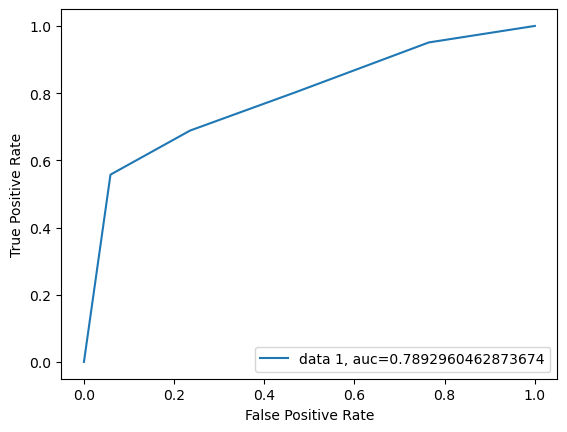


DT 73.07692307692307
0.32088621525634403
[[10  7]
 [14 47]]
              precision    recall  f1-score   support

         0.0       0.42      0.59      0.49        17
         1.0       0.87      0.77      0.82        61

    accuracy                           0.73        78
   macro avg       0.64      0.68      0.65        78
weighted avg       0.77      0.73      0.75        78



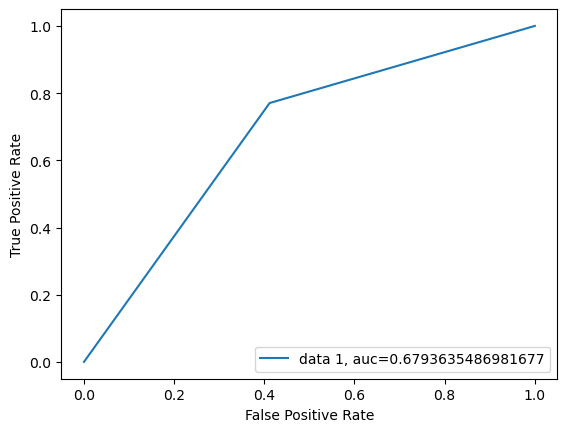


GB 69.23076923076923
0.16963886215057972
[[ 7 10]
 [14 47]]
              precision    recall  f1-score   support

         0.0       0.33      0.41      0.37        17
         1.0       0.82      0.77      0.80        61

    accuracy                           0.69        78
   macro avg       0.58      0.59      0.58        78
weighted avg       0.72      0.69      0.70        78



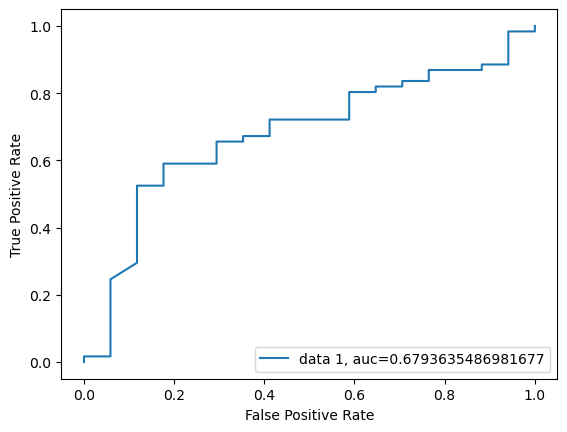

In [34]:
# evaluate each algorithm / model
results = []
names = []
print("Scores for each algorithm:")
for name, model in models:
    kfold = model_selection.KFold(n_splits = num_folds)
    cv_results = model_selection.cross_val_score(model, X_train, Y_train, cv = kfold, scoring = scoring)
    results.append(cv_results)
    names.append(name)
    model.fit(X_train, Y_train)
    predictions = model.predict(X_test)
    print(name, accuracy_score(Y_test, predictions)*100)
    print(matthews_corrcoef(Y_test, predictions))
    print(confusion_matrix(Y_test, predictions))
    print(classification_report(Y_test, predictions))
    y_pred_proba = model.predict_proba(X_test)[::,1]
    fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
    auc = roc_auc_score(Y_test, y_pred_proba)
    plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
    plt.ylabel('True Positive Rate')
    plt.xlabel('False Positive Rate')
    plt.legend(loc=4)
    plt.show()
    print()

### XGBoost Classifier

In [40]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
cross_val_score(XGBClassifier(), X, Y)

array([0.66666667, 0.76923077, 0.69230769, 0.69230769, 0.71794872])

In [12]:
np.mean(cross_val_score(XGBClassifier(), X, Y, cv=5, scoring='accuracy'))

0.8153846153846154

In [43]:
model = XGBClassifier()
model.fit(X_train, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [44]:
# make predictions for test data
y_pred = model.predict(X_test)

In [45]:
predictions = [round(value) for value in y_pred]

In [47]:
# evaluate predictions
accuracy = accuracy_score(Y_test, predictions)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 89.74%


In [49]:
print(matthews_corrcoef(Y_test, predictions))

0.7132374773966104


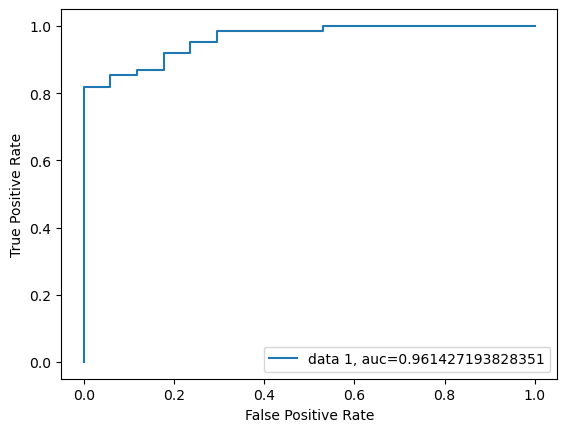

In [48]:
y_pred_proba = model.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()
print()

### CatBoost Classifier

In [14]:
from catboost import CatBoostClassifier, Pool

In [15]:
catboost_model = CatBoostClassifier(iterations=2,
                           depth=2,
                           learning_rate=1,
                           loss_function='Logloss',
                           verbose=True)

In [23]:
catboost_model.fit(X_train, Y_train)

0:	learn: 0.3150709	total: 64ms	remaining: 64ms
1:	learn: 0.2731184	total: 64.5ms	remaining: 0us


In [27]:
preds_class = catboost_model.predict(X_test)
preds_proba = catboost_model.predict_proba(X_test)

In [33]:
print(type(preds_proba))

<class 'numpy.ndarray'>


In [28]:
print(catboost_model.get_best_score())

{'learn': {'Logloss': 0.27311836246751314}}


In [30]:
import sys

In [20]:
results

[array([0.75      , 1.        , 0.83333333, 0.75      , 0.83333333,
        0.83333333, 0.83333333, 1.        , 0.81818182, 0.81818182]),
 array([0.83333333, 1.        , 0.75      , 0.83333333, 0.75      ,
        0.75      , 0.75      , 0.90909091, 0.90909091, 0.81818182]),
 array([0.58333333, 0.91666667, 0.75      , 0.83333333, 0.91666667,
        1.        , 0.91666667, 1.        , 0.90909091, 1.        ]),
 array([0.83333333, 1.        , 0.83333333, 0.83333333, 0.91666667,
        1.        , 0.91666667, 1.        , 0.81818182, 0.81818182])]

In [19]:
predictions = []
for instance in X_test:
    predictions.append(1)

print(accuracy_score(Y_test, predictions)*100)
print(matthews_corrcoef(Y_test, predictions))

78.2051282051282
0.0


In [27]:
results_df = pd.DataFrame(data = results, index = names)

In [28]:
results_df

,0,1,2,3,4,5,6,7,8,9
LR,0.750000,1.000000,0.833333,0.750000,0.833333,0.833333,0.833333,1.000000,0.818182,0.818182
KNN,0.833333,1.000000,0.750000,0.833333,0.750000,0.750000,0.750000,0.909091,0.909091,0.818182
DT,0.583333,0.916667,0.750000,0.833333,0.916667,1.000000,0.916667,1.000000,0.909091,1.000000
GB,0.833333,1.000000,0.833333,0.833333,0.916667,1.000000,0.916667,1.000000,0.818182,0.818182


(0.0, 1.0)

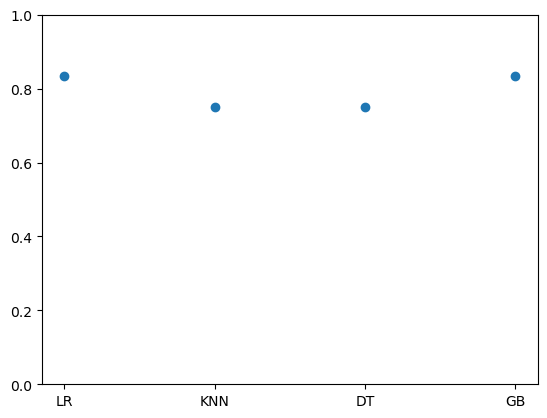

In [35]:
plt.scatter(x=names, y=results_df[2], cmap='viridis')
plt.ylim(0, 1)

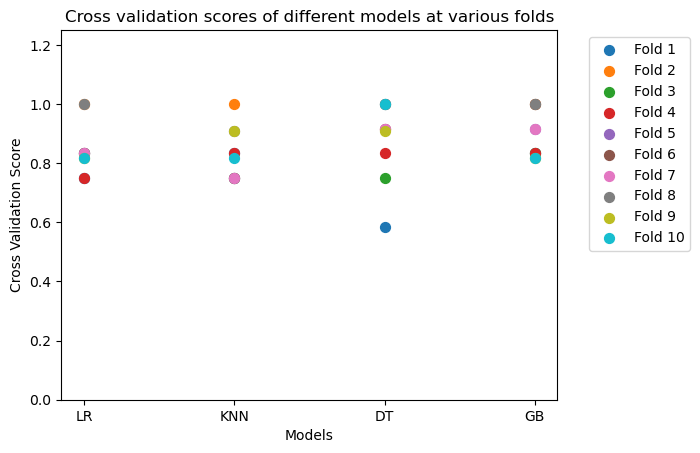

In [50]:
plt.scatter(names, results_df[0], label='Fold 1', s = 50)
plt.scatter(names, results_df[1], label='Fold 2', s = 50)
plt.scatter(names, results_df[2], label='Fold 3', s = 50)
plt.scatter(names, results_df[3], label='Fold 4', s = 50)
plt.scatter(names, results_df[4], label='Fold 5', s = 50)
plt.scatter(names, results_df[5], label='Fold 6', s = 50)
plt.scatter(names, results_df[6], label='Fold 7', s = 50)
plt.scatter(names, results_df[7], label='Fold 8', s = 50)
plt.scatter(names, results_df[8], label='Fold 9', s = 50)
plt.scatter(names, results_df[9], label='Fold 10', s = 50)
 
plt.xlabel("Models")
plt.ylabel("Cross Validation Score")
plt.title("Cross validation scores of different models at various folds")
plt.ylim(0, 1.25)
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
plt.show()

# XGBClassifier Using xgboost library

In [71]:
import xgboost as xgb
import sklearn.metrics as metrics
from sklearn.model_selection import GridSearchCV
from xgboost import plot_importance

In [72]:
# A function to create XGBoost models and perform cross-validation

def modelfit(alg, dtrain, predictors,useTrainCV=True, cv_folds=5, early_stopping_rounds=50):
    
    if useTrainCV:
        xgb_param = alg.get_xgb_params()
        xgtrain = xgb.DMatrix(dtrain[predictors].values, label=dtrain['status'].values)
        cvresult = xgb.cv(xgb_param, xgtrain, num_boost_round=alg.get_params()['n_estimators'], nfold=cv_folds,
            metrics='auc', early_stopping_rounds=early_stopping_rounds)
        alg.set_params(n_estimators=cvresult.shape[0])
    
    #Fit the algorithm on the data
    alg.fit(dtrain[predictors], dtrain['status'],eval_metric='auc')
        
    #Predict training set:
    dtrain_predictions = alg.predict(dtrain[predictors])
    dtrain_predprob = alg.predict_proba(dtrain[predictors])[:,1]
        
    #Print model report:
    print ("\nModel Report")
    print ("Accuracy : %.4g" % metrics.accuracy_score(dtrain['status'].values, dtrain_predictions))
    print ("AUC Score (Train): %f" % metrics.roc_auc_score(dtrain['status'], dtrain_predprob))
    
    plot_importance(alg)
                   
#     feat_imp = pd.Series(alg.Booster().get_fscore()).sort_values(ascending=False)
#     feat_imp.plot(kind='bar', title='Feature Importances')
#     plt.ylabel('Feature Importance Score')


Model Report
Accuracy : 0.9744
AUC Score (Train): 0.991922


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


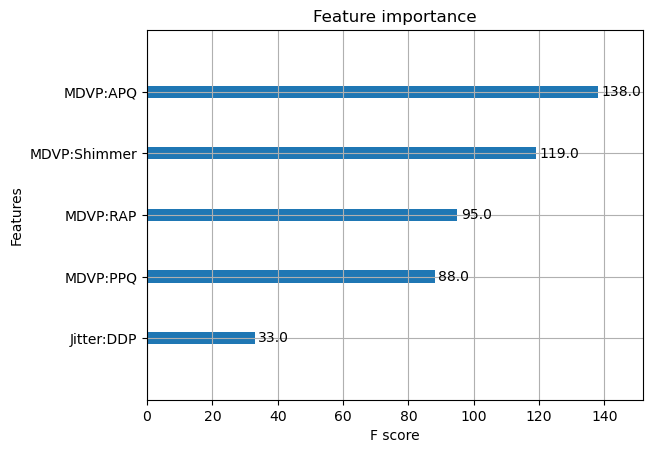

In [90]:
#Choose all predictors except target & IDcols
predictors = [x for x in dataset.columns if x not in ['status']]
xgb1 = XGBClassifier(
 learning_rate =0.1,
 n_estimators=50,
 max_depth=5,
 min_child_weight=1,
 gamma=0,
 subsample=0.8,
 colsample_bytree=0.8,
 objective= 'binary:logistic',
 nthread=4,
 scale_pos_weight=1,
 seed=27)
modelfit(xgb1, dataset, predictors)

In [82]:
param_test1 = {
 'max_depth':range(3,10,2),
 'min_child_weight':range(1,6,2),
 'n_estimators': range(50, 400, 50)
}
gsearch1 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1,
 gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27), 
 param_grid = param_test1, scoring='roc_auc',n_jobs=4,cv=5)
gsearch1.fit(dataset[predictors],dataset['status'])




GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=0, gpu_id=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.1, max_b...
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=5,
                                     max_leaves=None, min_child_weight=1,
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=100, n_jobs=None, nthread=4,
                                     num_parallel_tree=None, predictor=None, ...),
             n_jobs=4,
             param_grid={'max_depth': range(3, 10, 2),
                         'min_child_weight': range(1, 6, 2),
                         'n_estimators': range(50, 400, 50)},
             scoring='roc_auc')

In [83]:
gsearch1.cv_results_

{'mean_fit_time': array([0.04018731, 0.06147485, 0.08788848, 0.11257653, 0.14026279,
        0.16786451, 0.19357285, 0.02767501, 0.05342636, 0.0769608 ,
        0.10084   , 0.12278442, 0.14560189, 0.17233391, 0.02332506,
        0.04544377, 0.06788173, 0.09113326, 0.10812898, 0.12518325,
        0.14373937, 0.04156294, 0.07681179, 0.10840278, 0.13668451,
        0.16945844, 0.19762745, 0.22693233, 0.02978883, 0.05713029,
        0.08274364, 0.10428991, 0.13076015, 0.15029435, 0.17333894,
        0.02495122, 0.04833531, 0.06617041, 0.08710108, 0.10697093,
        0.1256813 , 0.14595985, 0.04604735, 0.07974653, 0.11483412,
        0.14661856, 0.18083668, 0.2028513 , 0.22564759, 0.03032656,
        0.05863252, 0.08165898, 0.11046958, 0.12615371, 0.15361099,
        0.1808104 , 0.02457418, 0.04487   , 0.06533523, 0.08693218,
        0.10631084, 0.12367525, 0.14357066, 0.0475328 , 0.08245912,
        0.11167526, 0.14376073, 0.17435565, 0.20045605, 0.23051276,
        0.0297226 , 0.05357914,

In [84]:
gsearch1.best_params_

{'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 50}

In [85]:
gsearch1.best_score_

0.7873052362707536

In [86]:
param_test2 = {
 'max_depth':[2,3,4],
 'min_child_weight':[4,5,6]
}
gsearch2 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, max_depth=5,
 min_child_weight=1, gamma=0, subsample=0.8, colsample_bytree=0.8, n_estimators=50,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27), 
 param_grid = param_test2, scoring='roc_auc',n_jobs=4,cv=5)
gsearch2.fit(dataset[predictors],dataset['status'])

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=0, gpu_id=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.1, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=5,
                                     max_leaves=None, min_child_weight=1,
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=50, n_jobs=None, nthread=4,
                                     num_parallel_tree=None, predictor=None, ...),
             n_jobs=4,
             param_grid={'max_depth': [2, 3, 4], 'min_child_weight': [4, 5, 6]},
             scoring='roc_auc')

In [88]:
gsearch2.best_params_

{'max_depth': 3, 'min_child_weight': 5}

In [89]:
gsearch2.best_score_

0.7873052362707536

In [91]:
param_test2b = {
    'min_child_weight': [6,8,10,12]
}

gsearch2b = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, max_depth=5,
 min_child_weight=1, gamma=0, subsample=0.8, colsample_bytree=0.8, n_estimators=50,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27), 
 param_grid = param_test2b, scoring='roc_auc',n_jobs=4,cv=5)
gsearch2b.fit(dataset[predictors],dataset['status'])

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=0, gpu_id=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.1, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=5,
                                     max_leaves=None, min_child_weight=1,
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=50, n_jobs=None, nthread=4,
                                     num_parallel_tree=None, predictor=None, ...),
             n_jobs=4, param_grid={'min_child_weight': [6, 8, 10, 12]},
             scoring='roc_auc')

In [92]:
gsearch2b.best_params_

{'min_child_weight': 12}

In [93]:
gsearch2b.best_score_

0.8027586206896553

In [100]:
param_test3 = {
 'gamma':[i/10.0 for i in range(0,5)]
}
gsearch3 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=12, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test3, scoring='roc_auc',n_jobs=4, cv=5)
gsearch3.fit(dataset[predictors],dataset['status'])
gsearch3.best_params_, gsearch3.best_score_

({'gamma': 0.0}, 0.8027586206896553)


Model Report
Accuracy : 0.8
AUC Score (Train): 0.849135


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


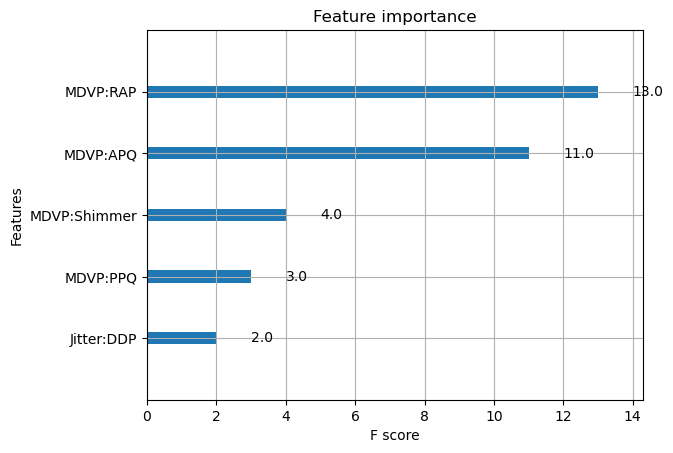

In [103]:
# Recaliberation

xgb2 = XGBClassifier(
 learning_rate =0.1,
 n_estimators=50,
 max_depth=3,
 min_child_weight=12,
 gamma=0,
 subsample=0.8,
 colsample_bytree=0.8,
 objective= 'binary:logistic',
 nthread=4,
 scale_pos_weight=1,
 seed=27)
modelfit(xgb2, dataset, predictors)

In [99]:
param_test4 = {
 'subsample':[i/10.0 for i in range(6,10)],
 'colsample_bytree':[i/10.0 for i in range(6,10)]
}

gsearch4 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=12, gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test4, scoring='roc_auc',n_jobs=4, cv=5)
gsearch4.fit(dataset[predictors],dataset['status'])
gsearch4.best_params_, gsearch4.best_score_

({'colsample_bytree': 0.8, 'subsample': 0.8}, 0.8027586206896553)

In [101]:
param_test6 = {
 'reg_alpha':[1e-5, 1e-2, 0.1, 1, 100]
}

gsearch6 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=12, gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test6, scoring='roc_auc',n_jobs=4, cv=5)
gsearch6.fit(dataset[predictors],dataset['status'])
gsearch6.best_params_, gsearch6.best_score_

({'reg_alpha': 1e-05}, 0.8027586206896553)

In [102]:
param_test7 = {
 'reg_alpha':[0, 0.001, 0.005, 0.01, 0.05]
}

gsearch7 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=12, gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test7, scoring='roc_auc',n_jobs=4, cv=5)
gsearch7.fit(dataset[predictors],dataset['status'])
gsearch7.best_params_, gsearch7.best_score_

({'reg_alpha': 0}, 0.8027586206896553)